In [1]:
# First, let's check which Python interpreter is being used by this notebook
import sys
print(f"Current Python executable: {sys.executable}")

# Let's see all available environments
!conda env list

# Let's check if we're in a conda environment and which one
import os
print(f"CONDA_DEFAULT_ENV: {os.environ.get('CONDA_DEFAULT_ENV', 'Not set')}")

# Let's try to install ortools directly in the current environment
!{sys.executable} -m pip install ortools

# After installation, try importing again
try:
    from ortools.constraint_solver import routing_enums_pb2
    from ortools.constraint_solver import pywrapcp
    print("Successfully imported ortools modules")
except ImportError as e:
    print(f"Import error: {e}")
!{sys.executable} -m pip install polars

Current Python executable: C:\Users\Administrator\.conda\envs\ml_env\python.exe

# conda environments:
#
base                   C:\ProgramData\anaconda3
ml_env               * C:\Users\Administrator\.conda\envs\ml_env
ml_env — копия         C:\Users\Administrator\.conda\envs\ml_env — копия

CONDA_DEFAULT_ENV: ml_env
Successfully imported ortools modules



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
from joblib import Parallel, delayed
import sqlite3
import polars as pl
from collections import defaultdict
import numpy as np
from ortools.constraint_solver import routing_enums_pb2
from ortools.constraint_solver import pywrapcp
import time
from tqdm import tqdm
import networkx as nx
import copy
import random
import pickle
from shapely.geometry import Polygon, Point
from shapely.ops import transform
from pyproj import Transformer
from typing import Dict, List, Tuple
import warnings
import json
import re

rng = np.random.default_rng (seed = 42)

MPID_df = pl.read_json('ml_ozon_logistic_dataSetOrders.json')

MPIDs_dict = defaultdict(list)
orders_dict = defaultdict(list)
orders_geo = defaultdict(list)

for item in MPID_df['Orders'].to_list():
    for order in item:
        if order['ID'] != 0:
            orders_geo[order['ID']] = {
                'lat': order['Lat'],
                'lon': order['Long']
            }
            MPIDs_dict[order['MpId']].append(order['ID'])
            orders_dict[order['ID']] = order['MpId']
        
MPIDs_list = list(MPIDs_dict.keys())

print(f"Загружено {len(orders_geo)} заказов, {len(MPIDs_list)} MPID")

def load_couriers_data(file_path):
    """Загружает данные о курьерах с координатами из Warehouse"""
    with open(file_path, 'r') as f:
        data = json.load(f)
    
    warehouse_geo = {
        'lat': data['Warehouse']['Lat'],
        'lon': data['Warehouse']['Long']
    }
    
    couriers = []
    for courier_group in data['Couriers']:
        courier_id = courier_group['ID']
        service_times = {}
        for service_time in courier_group['ServiceTimeInMps']:
            service_times[service_time['MpID']] = service_time['ServiceTime']
        
        couriers.append({
            'id': courier_id,
            'service_times': service_times
        })
    
    return warehouse_geo, couriers

warehouse_geo, couriers_data = load_couriers_data('ml_ozon_logistic_dataSetCouriers.json')
all_couriers_IDs = [c['id'] for c in couriers_data]

print(f"Загружено {len(couriers_data)} курьеров, склад: ({warehouse_geo['lat']}, {warehouse_geo['lon']})")

Загружено 20159 заказов, 1393 MPID
Загружено 280 курьеров, склад: (55.855153, 36.801776)


In [3]:
def create_sorted_distance_array():
    """Создает отсортированный массив расстояний с возможностью быстрого поиска"""
    conn = sqlite3.connect('distances.db')
    cursor = conn.cursor()

    # Получаем общее количество строк
    cursor.execute('SELECT COUNT(*) FROM distances')
    total_rows = cursor.fetchone()[0]

    # Создаем memory-mapped файл
    mmap_array = np.memmap('distances.dat', dtype=np.int32, mode='w+', shape=(total_rows, 3))

    # Загружаем данные из базы
    cursor.execute("SELECT from_location, to_location, distance FROM distances ORDER BY from_location, to_location")

    batch_size = 100000
    index = 0

    progress_bar = tqdm(total=total_rows, desc="Создание отсортированного массива", unit="row")

    while True:
        rows = cursor.fetchmany(batch_size)
        if not rows:
            break

        batch_array = np.array(rows, dtype=np.int32)
        mmap_array[index:index+len(batch_array)] = batch_array
        index += len(batch_array)

        progress_bar.update(len(rows))

    progress_bar.close()
    conn.close()

    return mmap_array

def create_search_index(distance_array):
    """Создает индекс для быстрого поиска по from_location"""
    # Находим уникальные from_location и их начальные позиции
    unique_from, start_indices = np.unique(distance_array[:, 0], return_index=True)

    # Создаем словарь для быстрого поиска диапазонов
    index_dict = {}
    for i in range(len(unique_from)):
        start = start_indices[i]
        end = start_indices[i+1] if i+1 < len(start_indices) else len(distance_array)
        index_dict[unique_from[i]] = (start, end)

    return index_dict

print("создание numpy сета расстояний из базы данных...")
start_time = time.time()

with open('distances.dat', 'rb') as f:
    data_bytes = f.read()
    
distance_array = np.frombuffer(data_bytes, dtype=np.int32).reshape(-1, 3)

# distance_array = create_sorted_distance_array()

idx_dict = create_search_index(distance_array)
cache_time = time.time() - start_time
print(f"Кэш создан за {cache_time:.2f} секунд, всего {len(distance_array)} записей")

создание numpy сета расстояний из базы данных...
Кэш создан за 5.55 секунд, всего 406405440 записей


In [4]:
def get_distance(distance_array, idx_dict, from_point, to_point, default=10**9):
    """Быстрое получение расстояния между двумя точками"""
    if from_point not in idx_dict:
        return default

    start, end = idx_dict[from_point]

    # Бинарный поиск в отсортированном диапазоне
    subset = distance_array[start:end]
    to_points = subset[:, 1]

    # Используем бинарный поиск NumPy
    pos = np.searchsorted(to_points, to_point)

    if pos < len(to_points) and to_points[pos] == to_point:
        return subset[pos, 2]
    else:
        return default

def create_distance_matrix(points, distance_array, idx_dict, poly_mapping=None, punishment=8000):
    """Создает матрицу расстояний для точек полигона с учетом штрафов между разными полигонами"""
    n = len(points)
    matrix = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            if i == j:
                matrix[i][j] = 0
            else:
                distance = get_distance(distance_array, idx_dict, points[i], points[j])
                
                if poly_mapping is not None:
                    poly_i = poly_mapping[points[i]]
                    poly_j = poly_mapping[points[j]]
                    
                    if poly_i != poly_j:
                        matrix[i][j] = distance + punishment
                    else:
                        matrix[i][j] = distance
                else:
                    matrix[i][j] = distance

    return matrix.astype(int).tolist()

In [5]:
import pickle
from collections import defaultdict

with open('optimized_solution_fast.pkl', 'rb') as file:
    final_solution = pickle.load(file)

with open('each_polygon_opt_route.pkl', 'rb') as file:
    final_each_polygon_opt_route = pickle.load(file)

new_couriers_dict = defaultdict()
for i in range(len(couriers_data)):
    new_couriers_dict[couriers_data[i]['id']] = couriers_data[i]['service_times']

brokens_list = []

In [6]:
### Augmentation part

In [7]:
#prepare full dataset
MPID_pl = pl.read_json('ml_ozon_logistic_dataSetOrders.json')

MPIDs_pl_dict = defaultdict(list)
for item in MPID_pl['Orders'].to_list():
    for order in item:
        MPIDs_pl_dict[order['ID']].extend([order['Lat'],order['Long']])

def refactor_dataset(dataset, polygon_tours):
    courier = copy.deepcopy(dataset)
    polygons = courier['New route']
    poly_tour = copy.deepcopy(polygon_tours)
    cost_count = 0
    cap = 7200
    SA_ID = 1
    new_polygons = defaultdict(list)
    
    for i,polygon in enumerate(polygons):
        if polygon == 0:
            LP_point = 0
            continue
        curr_polygon = {
            'points': poly_tour[polygon]['route'],
            'start point': poly_tour[polygon]['start_point'],
            'end point': poly_tour[polygon]['end_point'],
            'GIS distance': poly_tour[polygon]['total_distance']
        }
        cost_count+=curr_polygon['GIS distance']+get_distance(distance_array, idx_dict, LP_point, curr_polygon['start point'])
        if cost_count <= cap:
            new_polygons[SA_ID].append(curr_polygon)
            LP_point = curr_polygon['end point']
        else:
            SA_ID+=1
            LP_point=0
            cost_count=0
    return new_polygons

def unify_map(Map, UID = ''):
    new_map = {}   
    mask = 'NM-'
    count = 0
    
    for subroute in Map:
        UUID = UID+str(subroute)
        merged_points = []
        for polygon in Map[subroute]:
            if polygon['points'] == []:
                continue
            merged_points.extend(polygon['points'])
        if merged_points == []:
            continue
        pts_cloud = [MPIDs_pl_dict[point] for point in merged_points]
        new_map[UUID] = {'start point': merged_points[0],
                         'full map': merged_points,
                         'end point': merged_points[-1],
                         'points cloud': pts_cloud
                        }
    return new_map

def prepare_global_map(dataset, polygon_tours):
    global_map = {}
    oper_data = copy.deepcopy(dataset)
    mask = 'G-'
    iterator = 0

    for courier in oper_data:
        UID = mask+str(courier)+'-'
        Map = refactor_dataset(oper_data[courier], polygon_tours)
        ref_map = unify_map(Map, UID)
        global_map[UID] = ref_map

    return global_map

def map_distillation(Map):
    new_GM = copy.deepcopy(Map)
    distillated_map = {}    
    for item in Map:
        if global_map[item] == []:
            del new_GM[item]
        for pol in global_map[item]:
            if global_map[item][pol]['full map'] == []:
                del new_GM[item]
    return new_GM

def shape_df(Map):
    distil_map = copy.deepcopy(Map)
    global_G = defaultdict(list)
    
    for polygon in DM:
        A = np.array(create_distance_matrix(distil_map[polygon][0]['full map'], distance_array, idx_dict))
        G = nx.from_numpy_array(A)
        global_G[polygon] = G

    return global_G

In [8]:
class PolygonAnalyzer:
    """
    Geospatial polygon analysis for TAPOCB-BRMARL framework
    Calculates area, centroid, and relative position for each polygon_ID
    """
    
    def __init__(self, global_map: Dict):
        """
        Args:
            global_map: {polygon_ID: {'start point': int, 'full map': [IDs], 'end point': int, 'points cloud': [[lat, lon], ...]}}
        """
        self.global_map = global_map
        self.polygon_properties = {}
        
        # Transformer: WGS84 (lat/lon) → UTM (meters) for accurate area
        # UTM zone will be auto-detected per polygon
        self.wgs84_to_utm = None
        
    def _detect_utm_zone(self, lat: float, lon: float) -> int:
        """
        Detect UTM zone from coordinates
        """
        return int((lon + 180) / 6) + 1
    
    def _get_utm_transformer(self, lat: float, lon: float):
        """
        Create transformer for specific UTM zone
        """
        zone = self._detect_utm_zone(lat, lon)
        hemisphere = 'north' if lat >= 0 else 'south'
        
        transformer = Transformer.from_crs(
            f"EPSG:4326",  # WGS84 lat/lon
            f"EPSG:326{zone}" if hemisphere == 'north' else f"EPSG:327{zone}",  # UTM
            always_xy=True
        )
        return transformer
    
    def _calculate_geodesic_area(self, points_cloud: List[List[float]]) -> float:
        """
        Calculate polygon area in square meters using UTM projection
        
        Args:
            points_cloud: [[lat, lon], [lat, lon], ...]
        
        Returns:
            Area in m²
        """
        if len(points_cloud) < 3:
            return 0.0
        
        # Use centroid to detect UTM zone
        centroid_lat = np.mean([p[0] for p in points_cloud])
        centroid_lon = np.mean([p[1] for p in points_cloud])
        
        # Create transformer for this polygon's location
        transformer = self._get_utm_transformer(centroid_lat, centroid_lon)
        
        # Create Shapely polygon from lat/lon
        poly_lonlat = Polygon([(lon, lat) for lat, lon in points_cloud])
        
        # Transform to UTM (meters)
        poly_utm = transform(transformer.transform, poly_lonlat)
        
        # Calculate area in m²
        area_m2 = poly_utm.area
        
        return area_m2
    
    def _calculate_centroid(self, points_cloud: List[List[float]]) -> Tuple[float, float]:
        """
        Calculate polygon centroid (geographic center)
        
        Returns:
            (latitude, longitude) of centroid
        """
        if len(points_cloud) < 3:
            centroid_lat = np.mean([p[0] for p in points_cloud])
            centroid_lon = np.mean([p[1] for p in points_cloud])
            return centroid_lat, centroid_lon
        
        # Create polygon and get geometric centroid
        poly = Polygon([(lon, lat) for lat, lon in points_cloud])
        centroid = poly.centroid
        
        return centroid.y, centroid.x  # lat, lon
    
    def _calculate_bounding_box(self, points_cloud: List[List[float]]) -> Dict:
        """
        Calculate bounding box of polygon
        
        Returns:
            {min_lat, max_lat, min_lon, max_lon, width_km, height_km}
        """
        lats = [p[0] for p in points_cloud]
        lons = [p[1] for p in points_cloud]
        
        bbox = {
            'min_lat': min(lats),
            'max_lat': max(lats),
            'min_lon': min(lons),
            'max_lon': max(lons)
        }
        
        # Approximate dimensions in km
        bbox['height_km'] = (bbox['max_lat'] - bbox['min_lat']) * 111.32  # 1° lat ≈ 111.32 km
        bbox['width_km'] = (bbox['max_lon'] - bbox['min_lon']) * 111.32 * np.cos(np.radians(np.mean(lats)))
        
        return bbox
    
    def _calculate_relative_position(self, centroid: Tuple[float, float], 
                                     global_bounds: Dict) -> Dict:
        """
        Calculate polygon position relative to entire dataset
        
        Returns:
            {normalized_lat, normalized_lon, quadrant, distance_from_center_km}
        """
        cent_lat, cent_lon = centroid
        
        # Normalize to [0, 1] range
        norm_lat = (cent_lat / global_bounds['lat'])
        norm_lon = (cent_lon / global_bounds['lon'])
        
        # Determine quadrant
        if norm_lat >= 1 and norm_lon >= 1:
            quadrant = 'NE'
        elif norm_lat >= 1 and norm_lon < 1:
            quadrant = 'NW'
        elif norm_lat < 1 and norm_lon >= 1:
            quadrant = 'SE'
        elif norm_lat < 1 and norm_lon < 1:
            quadrant = 'SW'
        
        # Distance from global dataset center
        center_lat = global_bounds['lat']
        center_lon = global_bounds['lon']
        
        # Haversine distance
        distance_km = self._haversine_distance(cent_lat, cent_lon, center_lat, center_lon)
        
        return {
            'normalized_lat': norm_lat,
            'normalized_lon': norm_lon,
            'quadrant': quadrant,
            'distance_from_center_km': distance_km
        }
    
    def _haversine_distance(self, lat1: float, lon1: float, 
                            lat2: float, lon2: float) -> float:
        """
        Calculate great-circle distance between two points (in km)
        """
        R = 6371.0  # Earth radius in km
        
        lat1_rad = np.radians(lat1)
        lat2_rad = np.radians(lat2)
        delta_lat = np.radians(lat2 - lat1)
        delta_lon = np.radians(lon2 - lon1)
        
        a = np.sin(delta_lat/2)**2 + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(delta_lon/2)**2
        c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))
        
        return R * c
    
    def analyze_all_polygons(self) -> Dict:
        """
        Analyze all polygons in global_map
        
        Returns:
            {polygon_ID: {area_m2, area_km2, centroid, bbox, relative_position, ...}}
        """
        # First pass: calculate global bounds
        all_lats = []
        all_lons = []
        for poly_id, poly_data in self.global_map.items():
            points = poly_data['points cloud']
            all_lats.extend([p[0] for p in points])
            all_lons.extend([p[1] for p in points])
        
        global_bounds = {
            'lat': 55.333146,
            'lon': 37.224384,
        }
        
        # Second pass: analyze each polygon
        for poly_id, poly_data in self.global_map.items():
            points_cloud = poly_data['points cloud']
            point_ids = poly_data['full map']
            
            # Calculate properties
            area_m2 = self._calculate_geodesic_area(points_cloud)
            centroid = self._calculate_centroid(points_cloud)
            bbox = self._calculate_bounding_box(points_cloud)
            rel_pos = self._calculate_relative_position(centroid, global_bounds)
            
            # Store results
            self.polygon_properties[poly_id] = {
                'polygon_ID': poly_id,
                'num_points': len(point_ids),
                'point_ids': point_ids,
                'area_m2': area_m2,
                'area_km2': area_m2 / 1e6,
                'centroid_lat': centroid[0],
                'centroid_lon': centroid[1],
                'bounding_box': bbox,
                'relative_position': rel_pos,
                'points_cloud': points_cloud  # Keep for GNN conversion
            }
        
        return self.polygon_properties
    
    def export_to_json(self, filepath: str):
        """
        Export polygon properties to JSON for GNN training
        """
        with open(filepath, 'w') as f:
            json.dump(self.polygon_properties, f, indent=2)
    
    def get_polygon_clusters(self, n_clusters: int = 20) -> Dict:
        """
        Cluster polygons by spatial similarity (for GIN label generation)
        
        Args:
            n_clusters: Number of similarity classes
        
        Returns:
            {cluster_id: [polygon_IDs]}
        """
        from sklearn.cluster import KMeans
        from sklearn.preprocessing import StandardScaler
        
        # Features for clustering
        features = []
        poly_ids = []
        
        for poly_id, props in self.polygon_properties.items():
            feat = [
                props['area_km2'],
                props['centroid_lat'],
                props['centroid_lon'],
                props['bounding_box']['width_km'],
                props['bounding_box']['height_km'],
                props['relative_position']['normalized_lat'],
                props['relative_position']['normalized_lon']
            ]
            features.append(feat)
            poly_ids.append(poly_id)
        
        # Normalize and cluster
        scaler = StandardScaler()
        features_normalized = scaler.fit_transform(features)
        
        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
        cluster_labels = kmeans.fit_predict(features_normalized)
        
        # Group by cluster
        clusters = {}
        for poly_id, label in zip(poly_ids, cluster_labels):
            if label not in clusters:
                clusters[label] = []
            clusters[label].append(poly_id)
        
        # Add cluster labels to properties
        for poly_id, label in zip(poly_ids, cluster_labels):
            self.polygon_properties[poly_id]['cluster_label'] = int(label)
        
        return clusters

# TAPOCT REVISION: OSRM/OSM matrices replace synthetic augmentation distances.
# Originals retain operational OD distances; generated points use routable road distances.
from osm_distance_matrix import road_matrix, OSRMMatrixError
import hashlib
import json
from pathlib import Path

AUGMENTATION_REJECTIONS = []


def augment_polygon_geometric(points_cloud, full_map_ids, polygon, depot_latlon):
    """Return original and 9 spatial variants; each augmented OD uses OSRM Table."""
    from pyproj import Transformer
    raw = np.asarray(points_cloud, dtype=float)
    if raw.ndim != 2 or raw.shape[1] != 2 or len(raw) != len(full_map_ids):
        raise ValueError(f"Polygon {polygon}: point coordinates/IDs mismatch")
    center = np.mean(raw, axis=0)
    zone = int((center[1] + 180) / 6) + 1
    epsg = 32600 + zone if center[0] >= 0 else 32700 + zone
    forward = Transformer.from_crs(4326, epsg, always_xy=True)
    inverse = Transformer.from_crs(epsg, 4326, always_xy=True)
    xs, ys = forward.transform(raw[:, 1], raw[:, 0])
    xy = np.column_stack([xs, ys]); xy0 = np.mean(xy, axis=0)
    rng = np.random.default_rng(int(hashlib.sha256(str(polygon).encode()).hexdigest()[:16], 16))
    name = f'AUG-{polygon}-'
    original_matrix = np.asarray(create_distance_matrix(full_map_ids, distance_array, idx_dict), dtype=np.int64)
    if original_matrix.shape != (len(raw), len(raw)) or np.any(original_matrix >= 10**9):
        raise ValueError(f"Polygon {polygon}: original operational distance missing")
    result = {polygon: {
        'points cloud': raw.copy(),
        'full map': [name + f'-0-{oid}' for oid in full_map_ids],
        'distance matrix': original_matrix.tolist(),
        'augmented': False,
        'distance provenance': {'source': 'original_operational_OD', 'matrix_unit': 's',
                                'unit_basis': 'reported_by_dataset_owner'},
    }}
    transforms = [('rotation', angle) for angle in (45, 90, 135, 180, 225, 270, 315)]
    transforms += [('scale', scale) for scale in (0.8, 1.2)]
    for index, (kind, value) in enumerate(transforms, start=1):
        if kind == 'rotation':
            theta = np.deg2rad(value)
            rotation = np.array([[np.cos(theta), -np.sin(theta)],
                                 [np.sin(theta), np.cos(theta)]])
            shifted = (xy - xy0) @ rotation.T + xy0
        else:
            shifted = (xy - xy0) * value + xy0
        # Realistic small spatial displacement is applied to coordinates,
        # never independently to individual OD distances.
        shifted += rng.normal(0, 1.0, size=shifted.shape)
        lon, lat = inverse.transform(shifted[:, 0], shifted[:, 1])
        points = np.column_stack([lat, lon])
        variant_id = name + str(index)
        try:
            full, provenance = road_matrix(np.vstack([depot_latlon, points]), base_url="http://127.0.0.1:5000")
        except OSRMMatrixError as exc:
            # An incomplete OD matrix must never be passed to a routing solver.
            # Preserve the original polygon and other valid transformations.
            AUGMENTATION_REJECTIONS.append({
                'polygon': str(polygon), 'variant': variant_id,
                'transform': kind, 'transform_value': value,
                'reason': str(exc),
            })
            print(f'Rejected {variant_id}: {exc}')
            continue
        result[variant_id] = {
            'points cloud': points,
            'full map': [name + f'{index}-{oid}' for oid in full_map_ids],
            'distance matrix': full[1:, 1:].tolist(),
            'depot row': full[0, 1:].tolist(),
            'augmented': True,
            'distance provenance': {**provenance, 'geometry_transform': kind,
                                    'transform_value': value},
        }
    return result


def total_augmentation(source_map, depot_latlon=None):
    if depot_latlon is None:
        depot_latlon = (float(warehouse_geo['lat']), float(warehouse_geo['lon']))
    augmented_map = {}
    AUGMENTATION_REJECTIONS.clear()
    rejection_path = Path('augmentation_rejections_osrm_seconds.json')
    for polygon, record in source_map.items():
        variants = augment_polygon_geometric(record['points cloud'],
                                             record['full map'], polygon, depot_latlon)
        for variant_id, data in variants.items():
            augmented_map['AUG--' + variant_id] = data
        if AUGMENTATION_REJECTIONS:
            # Save diagnostics after each polygon, including on an interrupted run.
            temporary_path = rejection_path.with_suffix('.tmp')
            temporary_path.write_text(json.dumps(AUGMENTATION_REJECTIONS, indent=2,
                                                 ensure_ascii=False), encoding='utf-8')
            temporary_path.replace(rejection_path)
    if not AUGMENTATION_REJECTIONS and rejection_path.exists():
        rejection_path.unlink()
    print(f'Augmentation: {len(augmented_map)} retained records, '
          f'{len(AUGMENTATION_REJECTIONS)} rejected OSRM variants; '
          f'log: {rejection_path if AUGMENTATION_REJECTIONS else "none"}')
    return augmented_map


In [9]:
#Pipeline

MAP_FILE = 'AUG_global_map_osrm_seconds.pkl'
PROP_FILE = 'global_properties_osrm_seconds.pkl'

global_map = prepare_global_map(final_solution, final_each_polygon_opt_route)
DM = map_distillation(global_map)

global_map_new = {}
count = 0
for item in DM:
    for pol in DM[item]: 
        global_map_new[pol+"-"+str(count)] = DM[item][pol]
        count+=1

if os.path.exists(MAP_FILE):
    with open(MAP_FILE, 'rb') as f:
        AUG_global_map = pickle.load(f)
    if any(v.get('distance provenance', {}).get('matrix_unit') != 's' or (v.get('augmented') and ('depot row' not in v or v['distance provenance'].get('timing_source') != 'osrm_profile')) for v in AUG_global_map.values()):
        raise ValueError('Cached augmentation lacks OSRM travel times in seconds')
else:
    AUG_global_map = total_augmentation(global_map_new)
    with open(MAP_FILE, 'wb') as f:
        pickle.dump(AUG_global_map, f)

analyzer = PolygonAnalyzer(AUG_global_map)
properties = analyzer.analyze_all_polygons()

if os.path.exists(PROP_FILE):
    with open(PROP_FILE, 'rb') as f:
        properties = pickle.load(f)
else:
    properties = analyzer.analyze_all_polygons()
    with open(PROP_FILE, 'wb') as f:
        pickle.dump(properties, f)

clusters = analyzer.get_polygon_clusters(n_clusters=8)
print(f"Cluster 0 has {len(clusters[0])} polygons")

for polygon in AUG_global_map:
    for cluster, poly_ids in clusters.items():
        if polygon in poly_ids:
            AUG_global_map[polygon]['cluster'] = cluster

with open(MAP_FILE, 'wb') as f:
    pickle.dump(AUG_global_map, f)

C:\Users\Administrator\.conda\envs\ml_env\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Не удается найти указанный файл
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Administrator\.conda\envs\ml_env\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\Administrator\.conda\envs\ml_env\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\Administrator\.conda\envs\ml_env\lib\subprocess.py", line 971, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Administrator\.conda\envs\ml_env\lib\subprocess.py", line 1456, in _execute_child
    hp, ht, pid, tid = _winapi.Cre

Cluster 0 has 313 polygons


In [10]:
for cluster,obj in clusters.items():
    print(len(obj))

313
309
1051
2104
67
3
2
1


In [11]:
PREFERENCE_MAP = 'glob_pref_map.pkl'
if os.path.exists(PREFERENCE_MAP):
    with open(PREFERENCE_MAP, 'rb') as f:
        global_preferences = pickle.load(f)
else:
    global_preferences = {}  # generated for new polygons in cell 19

def get_basic_poly_ID(polygon):
    ID = re.split(r'-', polygon)
    for i in ID:
        if i.isnumeric():
            basic_ID = int(i)
            return basic_ID
        continue

def get_basic_order_ID(point):
    sliced_string = re.split(r'-', str(point))
    basic_point = sliced_string[-1]

    return int(basic_point)

def run_TAPOCB(agent_id, client_prefs, client_config, max_iter=1000, fitted_map=False, client_id=92):
    tender = client_config
    path = []

    basic_orders = [get_basic_order_ID(order) for order in tender['orders']]
    
    if fitted_map == False:
        ideal_matrix = np.array(create_distance_matrix(basic_orders, distance_array, idx_dict))
    else:
        ideal_matrix = np.array(fitted_map)

    config = TAPOCBConfig(learning_rate=0.02, eta=0.01, mu=1000.0, convergence_window=20, B=43200.0)
    
    sumo = SUMOInterface(traffic_alpha=2, traffic_beta=2, ideal_matrix=ideal_matrix)
    optimizer = OptimizerInterface()

    agent = TAPOCBAgent(
        agent_id=agent_id,
        config=config,
        sumo_interface=sumo,
        optimizer_interface=optimizer,
        dynamic_threshold=100
    )

    courier_position = 0
    orders = [courier_position] + tender['orders']

    start_t = time.time()
    
    for episode in range(max_iter):
        result = agent.step(
            client_prefs=client_prefs,
            orders=orders,
            time_window=tender['time_window'],
            polygon_id=tender['polygon_id'],
            client_id=tender['client_id'],
            U=tender['U'],
            price=tender['price'],
            CT_SA=tender['CT_SA'],
            additional=60 * len(tender['orders'])
        )
            
        print(f"  Политика: {[round(p, 3) for p in result['policy']]}")
        print(f"  Выбран: {result['chosen_algorithm']}")
        print(f"  W(a_t): {result['chosen_reward']:.2f}")
        print(f"  KL: {result['kl_divergence']:.4f}")
        print(f"  Сходимость: {result['converged']}")
    
        if result['converged']:
            print('Достигнута сходимость!')
            path = result['optimal_route']
            break
    return result, path

In [12]:
def get_elite_polygons(clusters):
    elite_polygons = defaultdict(list)
    
    for idx in range(len(clusters)-1):
        elite_polygons_list = []
        if len(clusters[idx]) > 200:
            pol_number = 20
        else:
            pol_number = round(len(clusters[idx])/10)
        while len(elite_polygons_list) < pol_number:
            new_polygon_idx = int(rng.integers(0,len(clusters[idx]),1))
            if np.isin(clusters[idx][new_polygon_idx],elite_polygons_list):
                continue
            elite_polygons_list.append(clusters[idx][new_polygon_idx])
        elite_polygons['EP'+str(idx)] = elite_polygons_list

    return elite_polygons

In [13]:
# TAPOCT REVISION: retain only data initialization and spatial index from old cell 19.
import os
import pickle
import numpy as np
from scipy.spatial import cKDTree

polygon_ids = list(properties)
centroid_coords = np.array([[properties[p]['centroid_lat'], properties[p]['centroid_lon']]
                            for p in polygon_ids])
spatial_tree = cKDTree(centroid_coords)
def get_nearest_polygons(lat, lon, k=15):
    k = min(int(k), len(polygon_ids))
    _, indices = spatial_tree.query([lat, lon], k=k)
    return [polygon_ids[int(i)] for i in np.atleast_1d(indices)]


In [16]:
# TAPOCT REVISION: run after cells 1–14, 16–19; no old cell 20 required.
# Place tapoct_fast.py, routing_solvers.py and osm_distance_matrix.py beside this notebook.
import importlib
import tapoct_fast as tf
importlib.reload(tf)

with open('glob_pref_map.pkl', 'rb') as f:
    GLOBAL_PREFERENCES_MAP = pickle.load(f)

cfg = tf.TAPOCTFastConfig(n_passes_min=2, n_passes_max=3,
                          label_mode='omd', max_gap=0.01, B=43200.0, seed=42)
def depot_row_fn(full_map_ids):
    """Original polygons only; augmented depot rows come from OSM in the map."""
    return [int(get_distance(distance_array, idx_dict, 0, get_basic_order_ID(o)))
            for o in full_map_ids]

dynamic_config = {'U': 900, 'price': 500, 'CT_SA': 5,
                  'time_window': (0.0, 7200.0)}
TAPOCB_EPOS = tf.get_exp_couriers(
    final_solution, get_nearest_polygons,
    max_couriers=1, checkpoint_every=20, dynamic_config=dynamic_config,
    k_polygons=3850, num_workers=6, aug_map=AUG_global_map,
    prefs_map=GLOBAL_PREFERENCES_MAP, depot_row_fn=depot_row_fn,
    solver_factory='routing_solvers:get_solvers', cfg=cfg,
    spec_kwargs={'service_time_per_order': 0.0},
)


In [21]:
import folium
import numpy as np
from scipy.spatial import Voronoi
from shapely.geometry import Polygon

# ==========================================
# 1. Dummy Data Setup 

# (Replace this block with your actual AUG_global_map and properties dictionaries)
# ==========================================
with open('epos_cache.pkl', 'rb') as f:
    EPOS_CACHE = pickle.load(f)

polygon_ids = EPOS_CACHE.keys()

# ==========================================
# 2. Data Extraction
# ==========================================
geo_data = []
coords = []

for pid in polygon_ids:
    cluster = float(AUG_global_map[pid]['cluster'])
    num_points = properties[pid]['num_points']
    area_km2 = properties[pid]['area_km2']
    lat = properties[pid]['centroid_lat']
    lon = properties[pid]['centroid_lon']
    alg = EPOS_CACHE[pid]['chosen_algorithm']
    
    # SciPy expects (x, y) which is (longitude, latitude)
    coords.append([lon, lat])
    
    geo_data.append({
        'polygon_id': pid,
        'cluster': cluster,
        'num_points': num_points,
        'area_km2': area_km2,
        'chosen_alg': alg
    })

points = np.array(coords)
n_real_points = len(points)

# ==========================================
# 3. Bug-Free SciPy Voronoi Generation
# ==========================================
# Trick: Add 4 dummy points far outside the valid global map range [-180, 180] x [-90, 90].
# This guarantees that all real points are inside the convex hull, preventing 
# SciPy from generating infinite regions (the dreaded '-1' vertex index bug).
dummy_points = np.array([
    [37.5, 54.5],
    [38.0, 54.5],
    [37.5,  57.0],
    [38.0,  57.0]
])

all_points = np.vstack([points, dummy_points])

# Add microscopic jitter to prevent QhullError in case of duplicate or collinear centroids
jitter = np.random.uniform(-1e-8, 1e-8, all_points.shape)
vor = Voronoi(all_points + jitter)

# Extract valid polygons only for the real points
geojson_features = []
for i in range(n_real_points):
    region_idx = vor.point_region[i]
    region_vertices_idx = vor.regions[region_idx]
    
    # Because of the dummy bounding box, '-1' (infinity) will not be present for real points
    if -1 not in region_vertices_idx:
        polygon_coords = vor.vertices[region_vertices_idx]
        
        # Create Shapely Polygon
        poly = Polygon(polygon_coords)
        
        # Safeguard: Fix minor numerical self-intersection issues if they occur
        if not poly.is_valid:
            poly = poly.buffer(0)
            
        if not poly.is_empty:
            geojson_features.append({
                'type': 'Feature',
                'geometry': poly.__geo_interface__,
                'properties': geo_data[i]
            })

# Create the final GeoJSON structure
geojson_data = {
    'type': 'FeatureCollection',
    'features': geojson_features
}

# ==========================================
# 4. Folium Map Creation
# ==========================================

m = folium.Map(
    location=[55.5, 37.5],
    zoom_start=10,
    tiles=f"https://{{s}}.basemaps.cartocdn.com/light_all/{{z}}/{{x}}/{{y}}.png?key={'cb1_55jj_1_1dbc7086842586b01a540463'}",
    attr="&copy; OpenStreetMap contributors, &copy; CARTO",
)

# Generate distinct colors for each unique cluster
unique_clusters = sorted(list(set(d['cluster'] for d in geo_data)))
color_palette = ['#e6194B', '#3cb44b', '#ffe119', '#4363d8', '#f58231', '#911eb4', '#42d4f4', '#f032e6', '#bfef45', '#fabed4']
cluster_colors = {cluster: color_palette[i % len(color_palette)] for i, cluster in enumerate(unique_clusters)}

def style_function(feature):
    cluster = feature['properties']['cluster']
    return {
        'fillColor': cluster_colors[cluster],
        'color': 'black',
        'weight': 1,
        'fillOpacity': 0.2
    }

def highlight_function(feature):
    return {
        'fillOpacity': 0.8,
        'weight': 2,
        'color': 'white'
    }

# Add GeoJSON layer with interactive tooltips
folium.GeoJson(
    geojson_data,
    style_function=style_function,
    highlight_function=highlight_function,
    tooltip=folium.features.GeoJsonTooltip(
        fields=['polygon_id', 'cluster', 'num_points', 'area_km2', 'chosen_alg'],
        aliases=['Polygon ID', 'Cluster', 'Number of Points', 'Area (km²)', 'Preferred algorithm'],
        localize=True,
        sticky=False,
        labels=True,
        style="""
            background-color: white;
            border: 1px solid gray;
            border-radius: 4px;
            padding: 8px;
            font-family: Arial, sans-serif;
            font-size: 12px;
            box-shadow: 2px 2px 5px rgba(0,0,0,0.2);
        """,
        max_width=300,
    )
).add_to(m)

# ==========================================
# 5. Add Cluster Color Legend (Bottom Left)
# ==========================================
legend_html = '''
<div style="position: fixed; 
     bottom: 30px; left: 30px; width: 160px; height: auto; 
     background-color: white; border: 2px solid grey; z-index: 9999; font-size: 14px;
     border-radius: 5px; padding: 10px; box-shadow: 2px 2px 5px rgba(0,0,0,0.3);">
     <p style="margin: 0 0 10px 0; font-weight: bold; text-align: center;">Cluster Legend</p>
'''

for cluster, color in cluster_colors.items():
    legend_html += f'''
    <p style="margin: 0; display: flex; align-items: center;">
        <span style="background: {color}; width: 16px; height: 16px; display: inline-block; margin-right: 8px; border: 1px solid black; border-radius: 3px;"></span>
        {cluster}
    </p>
    '''
legend_html += '</div>'

m.get_root().html.add_child(folium.Element(legend_html))

# Display the map (or use m.save("map.html") to export)
m
m.save("map.html")

In [22]:
reversed_poly2cluster_dict = defaultdict()

for cluster in clusters.keys():
    for poly_id in clusters[cluster]:
        reversed_poly2cluster_dict[poly_id] = cluster

In [23]:
clusters.keys()

dict_keys([np.int32(0), np.int32(7), np.int32(5), np.int32(2), np.int32(3), np.int32(4), np.int32(6), np.int32(1)])

In [24]:
for key in clusters.keys():
    print(len(clusters[key]))

313
309
1051
2104
67
3
2
1


In [25]:
least_pts = 200
most_pts = 1

for poly in properties.keys():
    if properties[poly]['num_points'] < least_pts:
        least_pts = properties[poly]['num_points']
    elif properties[poly]['num_points'] > most_pts:
        most_pts = properties[poly]['num_points']
    else:
        continue

In [26]:
most_pts

110

In [27]:
quads_per_cluster = defaultdict()

for cluster in clusters.keys():
    quadrants = defaultdict()
    for poly in clusters[cluster]:
        quad = properties[poly]['relative_position']['quadrant']
        if quad not in quadrants.keys():
            quadrants[quad] = 1
        else:
            quadrants[quad]+=1
    quads_per_cluster[cluster] = quadrants

In [28]:
summary = defaultdict()

for cluster in clusters.keys():
    summ_up = {
        'num_points': 0,
        'area': 0,
        'dist_from_center': 0,
        'quadrant': None
    }
    common_quads = list(quads_per_cluster[cluster].keys())
    summ_up['num_points'] = np.round(np.mean([properties[cid]['num_points'] for cid in clusters[cluster]]),0)
    summ_up['area'] = np.round(np.mean([properties[cid]['area_km2'] for cid in clusters[cluster]]),2)
    summ_up['dist_from_center'] = np.round(np.mean([properties[cid]['relative_position']['distance_from_center_km'] for cid in clusters[cluster]]),2)
    if len(common_quads)>1:
        summ_up['quadrant'] = f'{common_quads[0]}-{common_quads[1]}'
    else:
        summ_up['quadrant'] = common_quads[0]
    summary[cluster] = summ_up

In [29]:
summary

defaultdict(None,
            {np.int32(0): {'num_points': np.float64(45.0),
              'area': np.float64(7.47),
              'dist_from_center': np.float64(55.85),
              'quadrant': 'NW-NE'},
             np.int32(7): {'num_points': np.float64(46.0),
              'area': np.float64(7.34),
              'dist_from_center': np.float64(53.97),
              'quadrant': 'NW-NE'},
             np.int32(5): {'num_points': np.float64(37.0),
              'area': np.float64(2.26),
              'dist_from_center': np.float64(59.02),
              'quadrant': 'NW-NE'},
             np.int32(2): {'num_points': np.float64(30.0),
              'area': np.float64(0.23),
              'dist_from_center': np.float64(44.06),
              'quadrant': 'NW-NE'},
             np.int32(3): {'num_points': np.float64(68.0),
              'area': np.float64(37.57),
              'dist_from_center': np.float64(50.62),
              'quadrant': 'NE-NW'},
             np.int32(4): {'num_points': 

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

with open('courier_training_checkpoint_fd_seconds.pkl', 'rb') as f:
    TAPOCB_EPOS = pickle.load(f)

prop_data = {
    'polygon id': [],
    'cluster id': [],
    'lat': [],
    'lon': [],
    'num points': [],
    'area_km2': [],
    'dist from center': []
}
for cluster_id, _ in clusters.items():
    for polygon_id in clusters[cluster_id]:
        prop_data['polygon id'].append(polygon_id),
        prop_data['cluster id'].append(cluster_id),
        prop_data['lat'].append(float(properties[polygon_id]['centroid_lat'])),
        prop_data['lon'].append(properties[polygon_id]['centroid_lon']),
        prop_data['num points'].append(properties[polygon_id]['num_points'])
        prop_data['area_km2'].append(properties[polygon_id]['area_km2']),
        prop_data['dist from center'].append(properties[polygon_id]['relative_position']['distance_from_center_km'])

broken_polygons = ['AUG--AUG-G-169-19-167-7', 'AUG--AUG-G-57-10-314-2', 'AUG--AUG-G-128-4-84-3', 'AUG--AUG-G-119-13-145-5', 'AUG--AUG-G-119-13-145-4', 'AUG--AUG-G-35-6-5-5', 'AUG--AUG-G-121-6-152-6', 'AUG--AUG-G-426-5-280-4', 'AUG--AUG-G-73-5-123-2', 'AUG--AUG-G-426-5-280-5', 'AUG--AUG-G-28-2-335-2', 'AUG--AUG-G-169-6-164-7', 'AUG--AUG-G-28-2-335-1', 'AUG--AUG-G-426-5-280-8', 'AUG--AUG-G-426-7-282-2', 'AUG--AUG-G-169-6-164-6', 'AUG--G-426-5-280', 'AUG--AUG-G-73-5-123-4', 'AUG--AUG-G-202-6-93-7', 'AUG--AUG-G-72-12-64-6', 'AUG--AUG-G-72-12-64-3', 'AUG--AUG-G-72-12-64-9', 'AUG--G-72-12-64', 'AUG--G-236-14-379', 'AUG--AUG-G-236-14-379-2', 'AUG--AUG-G-140-2-99-2', 'AUG--G-216-4-28', 'AUG--AUG-G-236-14-379-9', 'AUG--AUG-G-73-3-121-7', 'AUG--AUG-G-85-4-20-1', 'AUG--AUG-G-67-3-35-8', 'AUG--AUG-G-426-4-279-9', 'AUG--AUG-G-354-6-49-4', 'AUG--AUG-G-390-2-244-5', 'AUG--AUG-G-14-3-111-2', 'AUG--AUG-G-347-3-228-4', 'AUG--AUG-G-62-1-67-1', 'AUG--AUG-G-249-4-329-6', 'AUG--AUG-G-351-1-229-3', 'AUG--AUG-G-344-1-219-3', 'AUG--AUG-G-27-1-330-5', 'AUG--AUG-G-67-2-34-9']

strat_data = {
    'cluster id': [],
    'polygon id': [],
    'MatNet': [],
    'NLNS_lkh': [],
    'LKH-3': [],
    'Christofides': []
}

for item in TAPOCB_EPOS.keys():
    for polygon_id in TAPOCB_EPOS[item]['polygon_list']:
        try:
            if polygon_id not in broken_polygons:
                strat_data['cluster id'].append(reversed_poly2cluster_dict[polygon_id])
                strat_data['polygon id'].append(polygon_id)
                strat_data['MatNet'].append(TAPOCB_EPOS[item]['EPOS_local_strat'][polygon_id][0])
                strat_data['NLNS_lkh'].append(TAPOCB_EPOS[item]['EPOS_local_strat'][polygon_id][1])
                strat_data['LKH-3'].append(TAPOCB_EPOS[item]['EPOS_local_strat'][polygon_id][2])
                strat_data['Christofides'].append(TAPOCB_EPOS[item]['EPOS_local_strat'][polygon_id][3])
            else:
                continue
        except Exception as e:
            bloken_polygons.append(polygon_id)
            print(e)

prop_df = pd.DataFrame(prop_data)

Christofides       Axes(0.125,0.11;0.168478x0.77)
LKH-3           Axes(0.327174,0.11;0.168478x0.77)
MatNet          Axes(0.529348,0.11;0.168478x0.77)
NLNS_lkh        Axes(0.731522,0.11;0.168478x0.77)
dtype: object

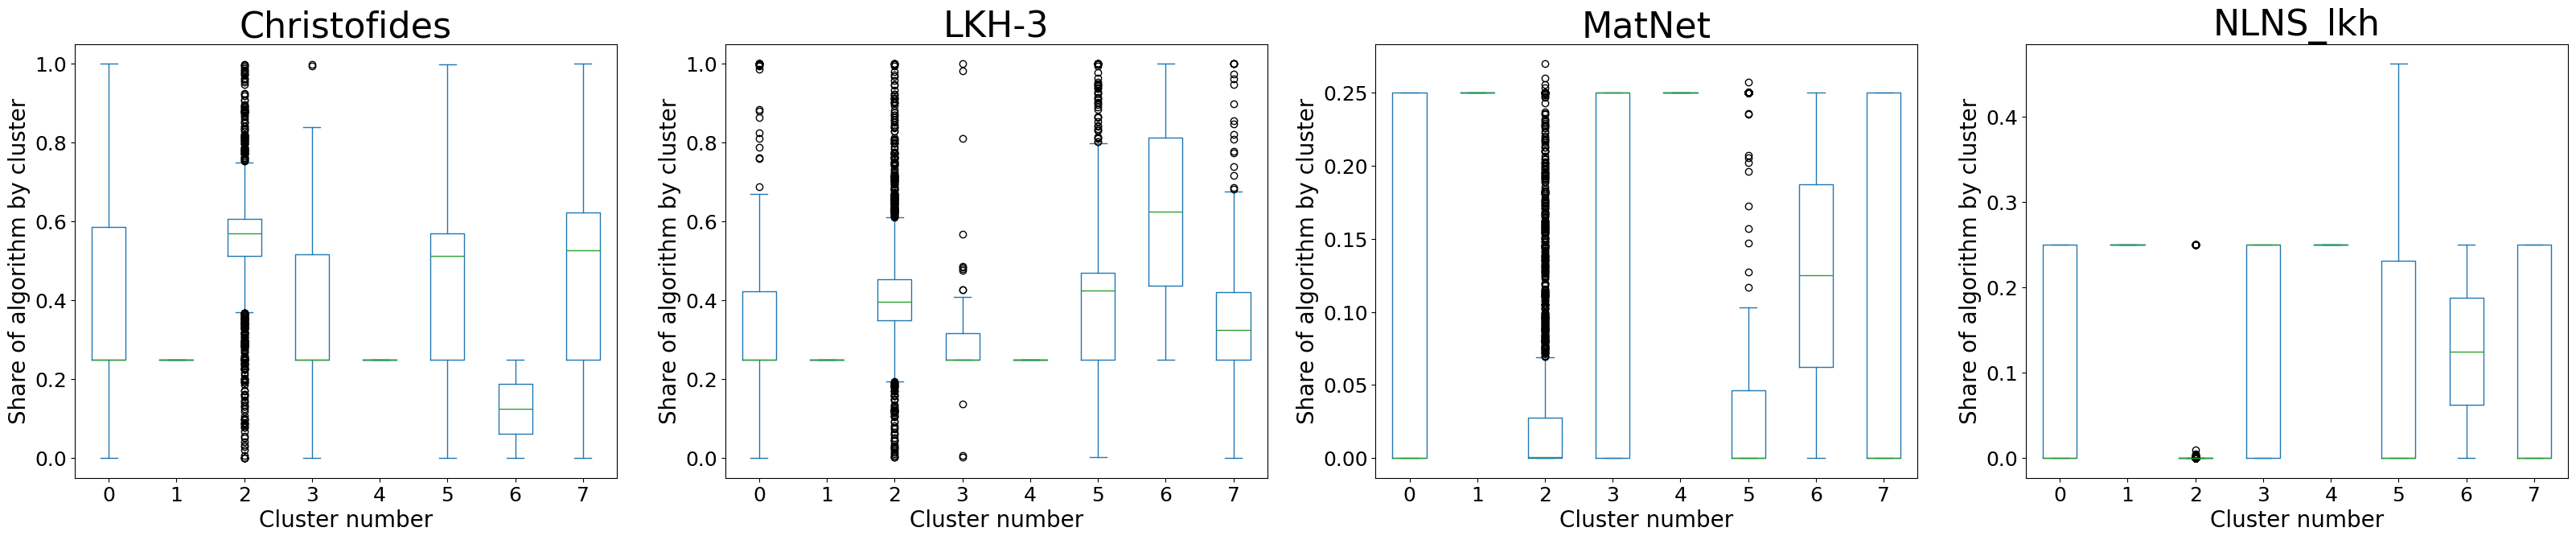

In [31]:
plt.rcParams['axes.titlesize'] = 32
plt.rcParams['axes.labelsize'] = 20

strat_df = pd.DataFrame(strat_data)
strat_df.plot.box(by = ['cluster id'], figsize = (40,7),
                 xlabel = 'Cluster number', ylabel = 'Share of algorithm by cluster',
                 fontsize = 18)

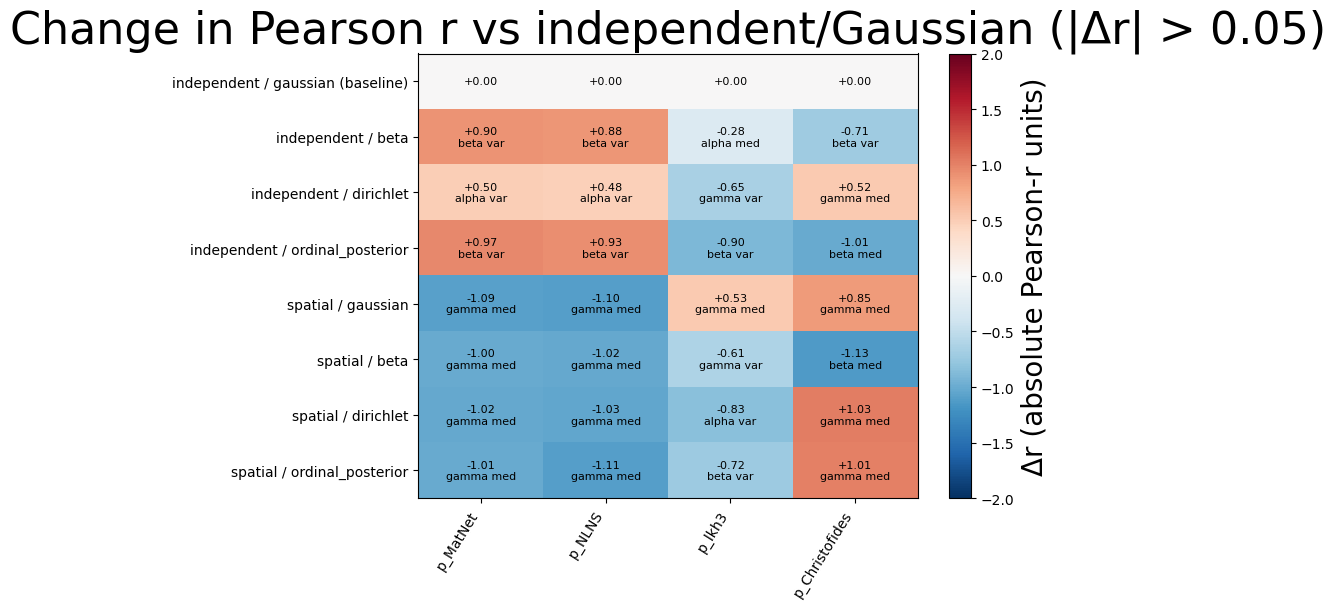

In [33]:
import pickle
from TAPOCT_robustness_cell import (
    run_distribution_robustness,
    cluster_correlation_matrices,
    scenario_performance,
    plot_correlation_matrices,
    plot_cluster_policies,
)

with open(tf.CACHE_FILE, "rb") as f:
    base_results = pickle.load(f)

pref_maps, policies, cluster_summary, cluster_params, diagnostics = (
    run_distribution_robustness(
        base_results, AUG_global_map, properties, cfg,
        seeds=(41, 42, 43),
        city_center=(55.333146, 37.224384),
    )
)

correlations = cluster_correlation_matrices(
    cluster_summary, cfg.algorithms, threshold=0.05
)

fig = plot_correlation_matrices(correlations)
fig.savefig("tapoct_pearson_highlights.png", dpi=300, bbox_inches="tight")

cluster_summary.to_csv("cluster_summary.csv", index=False)
correlations["full"].to_csv("pearson_full_appendix.csv")

Completed market scenario: independent/gaussian
Completed market scenario: independent/beta
Completed market scenario: independent/dirichlet
Completed market scenario: independent/ordinal_posterior
Completed market scenario: spatial/gaussian
Completed market scenario: spatial/beta
Completed market scenario: spatial/dirichlet
Completed market scenario: spatial/ordinal_posterior


,scenario,method,mean_bid,win_pct_all_tenders,mean_income_per_tender,mean_base_payment_per_tender,mean_client_satisfaction_contribution,mean_social_welfare_contribution
0,independent/gaussian,TAPOCB-NN,662.780840,19.34,90.717788,8.616151,0.133633,82.479323
1,independent/gaussian,LKH-3,661.479214,13.41,65.792780,8.599230,0.089821,56.793816
2,independent/gaussian,MatNet,666.724637,1.54,15.308458,8.667420,0.010484,6.471969
3,independent/gaussian,Regression,664.615142,16.63,80.310514,8.639997,0.113077,69.697005
4,independent/gaussian,NeuralUCB,666.784626,11.48,57.225646,8.668200,0.075759,49.060418
5,independent/gaussian,NeuralTS,663.386336,14.56,69.959559,8.624022,0.098858,62.541841
6,independent/gaussian,NeuralRBMLE-PC,661.418634,13.40,64.971820,8.598442,0.089786,57.583221
7,independent/beta,TAPOCB-NN,663.661443,17.95,83.715604,8.627599,0.121005,77.615553
8,independent/beta,LKH-3,661.495323,13.74,66.633826,8.599439,0.090844,58.736010
9,independent/beta,MatNet,667.204627,1.46,14.952496,8.673660,0.009931,6.168795


,method,mean_bid,win_pct_all_tenders,mean_income_per_tender,mean_base_payment_per_tender,mean_client_satisfaction_contribution,mean_social_welfare_contribution
0,TAPOCB-NN,664.206849,18.00500,84.287991,8.634689,0.124897,77.503112
1,LKH-3,661.229805,13.30000,64.911974,8.595987,0.089222,56.711042
2,MatNet,668.682450,1.59750,15.535034,8.692872,0.011237,6.759174
3,Regression,663.904694,18.12625,86.250480,8.630761,0.125878,76.521375
4,NeuralUCB,666.298898,12.72750,62.370392,8.661886,0.086242,54.529750
5,NeuralTS,663.827186,14.28750,68.848312,8.629753,0.098093,61.313819
6,NeuralRBMLE-PC,662.449282,12.31625,60.425361,8.611841,0.083583,52.981103


,scenario,n_tenders,allocation_rate_pct,mean_client_satisfaction,mean_total_base_payments,mean_social_welfare
0,independent/gaussian,10000,90.36,0.611419,60.413463,384.627593
1,independent/beta,10000,90.36,0.604544,60.420789,388.877812
2,independent/dirichlet,10000,90.36,0.613009,60.507130,388.769015
3,independent/ordinal_posterior,10000,90.36,0.598177,60.436148,388.150501
4,spatial/gaussian,10000,90.36,0.638374,60.418424,378.970099
5,spatial/beta,10000,90.36,0.629522,60.462210,387.872963
6,spatial/dirichlet,10000,90.36,0.627391,60.475246,387.123510
7,spatial/ordinal_posterior,10000,90.36,0.630782,60.528904,386.163513


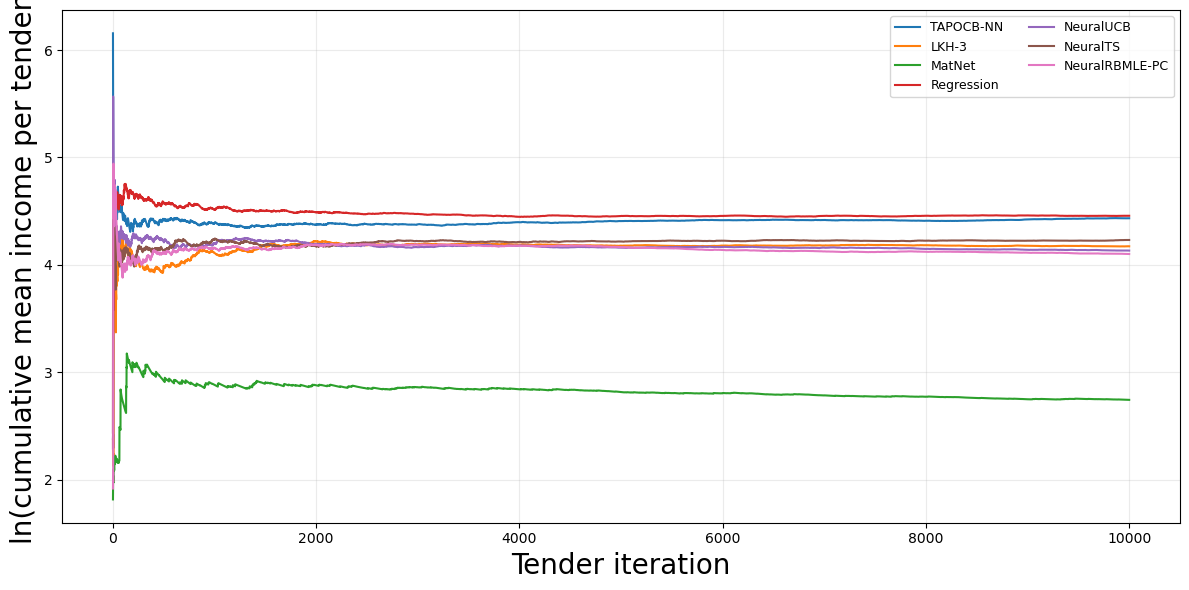

In [42]:
# Reuse the eight paired SOTA routing traces and generate the same preference maps.
# This experiment updates pricing agents, but holds measured route offers fixed.
import json
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import portfolio_sota as ps
import TAPOCT_robustness_cell as rb
import seven_agent_market as market7

importlib.reload(market7)

SEVEN_AGENT_MARKET_OUT = Path('seven_agent_market_eight_scenarios')
SEVEN_AGENT_MARKET_SEED = 42
SEVEN_AGENT_MARKET_ITERATIONS = 10_000
SEVEN_AGENT_BASE_REWARD_RATE = .013
MARKET_SCENARIOS = [(mode, dist) for mode in rb.SPATIAL_MODES for dist in rb.SCENARIOS]
prior_results = Path('portfolio_sota_comparison')
rule_path = prior_results / 'tapocb_policy_rule.json'
if not rule_path.is_file():
    raise FileNotFoundError('Complete the eight-scenario Portfolio_SOTA_training sweep first')
rule = json.loads(rule_path.read_text(encoding='utf-8'))
if (rule.get('version') != ps.TAPOCB_POLICY_RULE_VERSION or
        rule.get('scenarios') != [list(pair) for pair in MARKET_SCENARIOS]):
    raise ValueError('Routing traces must match the current TAPOCB policy and all eight scenarios')
raw_paths = {(mode, dist): prior_results / f'raw_{mode}_{dist}.csv'
             for mode, dist in MARKET_SCENARIOS}
missing = [str(p) for p in raw_paths.values() if not p.is_file()]
if missing:
    raise FileNotFoundError(f'Missing paired routing traces: {missing}')

def _load_market_pickle(path):
    with open(path, 'rb') as stream:
        return pickle.load(stream)

market_aug = _load_market_pickle('AUG_global_map_osrm_seconds.pkl')
market_properties = _load_market_pickle('global_properties_osrm_seconds.pkl')
market_epos = _load_market_pickle('epos_cache_fd.pkl')
market_gauss = _load_market_pickle('glob_pref_map.pkl')
market_replay = rb.common_triplet_replay(market_epos, ps.ALGORITHMS)
market_maps, _, _ = rb.preference_maps(
    market_replay, market_aug, market_properties, seed=SEVEN_AGENT_MARKET_SEED,
    gaussian_reference=market_gauss)

scenario_agent_tables = []
scenario_market_tables = []
running_sum = np.zeros((SEVEN_AGENT_MARKET_ITERATIONS, len(market7.METHODS)), dtype=float)
for mode, dist in MARKET_SCENARIOS:
    label = f'{mode}/{dist}'
    trace = market7.paired_route_trace(
        pd.read_csv(raw_paths[(mode, dist)]), scenario=label,
        n_tenders=SEVEN_AGENT_MARKET_ITERATIONS)
    prefs = market_maps[mode][dist]
    # Reset each agent for each scenario; identical actor/critic initialization.
    agents = {name: market7.BetaActorCriticBidder(seed=SEVEN_AGENT_MARKET_SEED)
              for name in market7.METHODS}
    agent_table, market_total, market_curve, market_offers = market7.simulate_market(
        trace, prefs, market_epos, agents, seed=SEVEN_AGENT_MARKET_SEED,
        base_reward_rate=SEVEN_AGENT_BASE_REWARD_RATE)
    assert len(agent_table) == len(market7.METHODS)
    assert len(market_curve) == SEVEN_AGENT_MARKET_ITERATIONS
    assert np.isclose(agent_table['mean_client_satisfaction_contribution'].sum(),
                      market_total['mean_client_satisfaction'].iloc[0])
    assert np.isclose(agent_table['mean_social_welfare_contribution'].sum(),
                      market_total['mean_social_welfare'].iloc[0])
    agent_table.insert(0, 'scenario', label)
    market_total.insert(0, 'scenario', label)
    market7.save_scenario_outputs(agent_table, market_total, market_curve, market_offers,
                                  SEVEN_AGENT_MARKET_OUT / f'{mode}_{dist}')
    scenario_agent_tables.append(agent_table)
    scenario_market_tables.append(market_total)
    running_sum += market_curve[list(market7.METHODS)].to_numpy(dtype=float)
    print('Completed market scenario:', label)
    del trace, prefs, agents, agent_table, market_total, market_curve, market_offers

market_56 = pd.concat(scenario_agent_tables, ignore_index=True)
market_totals_8 = pd.concat(scenario_market_tables, ignore_index=True)
market_running_8 = pd.DataFrame(running_sum / len(MARKET_SCENARIOS),
                                columns=market7.METHODS)
market_running_8.insert(0, 'iteration',
                         np.arange(1, SEVEN_AGENT_MARKET_ITERATIONS + 1))
market_7, fig = market7.save_eight_scenario_report(
    market_56, market_totals_8, market_running_8, SEVEN_AGENT_MARKET_OUT)
display(market_56)
display(market_7)
display(market_totals_8)
display(fig)
plt.close(fig)

